# Ecuación Black-Scholes

In [2]:
import sympy as sp
from IPython.display import display, Math
sp.init_printing(use_latex='mathjax')

Defino las variables $S,t,T, \tau , x$ como simbolos de sympy

In [ ]:

S, t, T, tau = sp.symbols('S t T tau', positive=True, real=True)


Defino también las variables $\sigma , r, q, E$ :

In [4]:
x = sp.Symbol('x', real=True)
sigma, r, q, E = sp.symbols('sigma r q E', positive=True, real=True)
alpha, beta = sp.symbols('alpha beta', real=True)

Se define la función original $V(S,t)$

In [5]:
V = sp.Function('V')(S, t)

La ecuación diferencial parcial de Black and Scholes

In [6]:
edp_bs = sp.diff(V, t) + sp.Rational(1, 2)*sigma**2 * S**2 * sp.diff(V, S, 2) + (r - q)*S * sp.diff(V, S) - r*V

print("Ecuación (1) de Black-Scholes:")
display(sp.Eq(edp_bs, 0))

Ecuación (1) de Black-Scholes:


       2                                                                 
 2  2 ∂                                                                  
S ⋅σ ⋅───(V(S, t))                                                       
        2                                                                
      ∂S                        ∂                         ∂              
────────────────── + S⋅(-q + r)⋅──(V(S, t)) - r⋅V(S, t) + ──(V(S, t)) = 0
        2                       ∂S                        ∂t             

Ahora se define la función:
$$
W(S, \tau)
$$

Donde: $ \tau = T- t$

In [7]:
W = sp.Function('W')(S, tau)

Usando la regla de la cadena: 
$$
\frac{dV}{dt} = \frac{dW}{d\tau} \cdot \frac{d\tau}{dt} = - \frac{dW}{d\tau}
$$

y las derivadas respecto a S no cambian.

In [8]:
edp_paso1 = edp_bs.subs({
    sp.diff(V, t): -sp.diff(W, tau),
    sp.diff(V, S, 2): sp.diff(W, S, 2),
    sp.diff(V, S): sp.diff(W, S),
    V: W
})

In [9]:
edp_paso1

       2                                                             
 2  2 ∂                                                              
S ⋅σ ⋅───(W(S, τ))                                                   
        2                                                            
      ∂S                        ∂                         ∂          
────────────────── + S⋅(-q + r)⋅──(W(S, τ)) - r⋅W(S, τ) - ──(W(S, τ))
        2                       ∂S                        ∂τ         

Multiplicando por -1 para dejar $\frac{dW}{d\tau}$ positivo

In [10]:
edp_paso1 = sp.simplify(-edp_paso1)
display(sp.Eq(edp_paso1, 0))

         2                                                                
   2  2 ∂                                                                 
  S ⋅σ ⋅───(W(S, τ))                                                      
          2                                                               
        ∂S                       ∂                         ∂              
- ────────────────── + S⋅(q - r)⋅──(W(S, τ)) + r⋅W(S, τ) + ──(W(S, τ)) = 0
          2                      ∂S                        ∂τ             

Ahora se define 
$$Z(x, \tau) = W(e^x, \tau)$$

In [11]:
Z = sp.Function('Z')(x, tau)

Se aplica la regla de la cadena, para tener
$$\frac{dW}{dS} = \frac{1}{S} \frac{dZ}{dx}$$
$$\frac{d^2W}{dS^2} = \frac{1}{S^2} \left( \frac{d^2Z}{dx^2} - \frac{dZ}{dx} \right)$$

In [12]:

dW_dS = (1/S) * sp.diff(Z, x)
d2W_dS2 = (1/S**2) * (sp.diff(Z, x, 2) - sp.diff(Z, x))

edp_paso2 = edp_paso1.subs({
    sp.diff(W, tau): sp.diff(Z, tau),
    sp.diff(W, S, 2): d2W_dS2,
    sp.diff(W, S): dW_dS,
    W: Z
})


In [13]:
edp_paso2

               ⎛                 2          ⎞                                  ↪
             2 ⎜  ∂             ∂           ⎟                                  ↪
            σ ⋅⎜- ──(Z(x, τ)) + ───(Z(x, τ))⎟                                  ↪
               ⎜  ∂x              2         ⎟                                  ↪
               ⎝                ∂x          ⎠           ∂             ∂        ↪
r⋅Z(x, τ) - ───────────────────────────────── + (q - r)⋅──(Z(x, τ)) + ──(Z(x,  ↪
                            2                           ∂x            ∂τ       ↪

↪    
↪    
↪    
↪    
↪    
↪ τ))
↪    

Simplificando terminos tenemos:

In [14]:
edp_paso2 = sp.collect(sp.expand(edp_paso2), [sp.diff(Z, tau), sp.diff(Z, x, 2), sp.diff(Z, x), Z])


display(sp.Eq(edp_paso2, 0))

                2                                                       
             2 ∂                                                        
            σ ⋅───(Z(x, τ))                                             
                 2            ⎛         2⎞                              
               ∂x             ⎜        σ ⎟ ∂             ∂              
r⋅Z(x, τ) - ─────────────── + ⎜q - r + ──⎟⋅──(Z(x, τ)) + ──(Z(x, τ)) = 0
                   2          ⎝        2 ⎠ ∂x            ∂τ             

In [15]:
u = sp.Function('u')(x, tau)


sustitucion del paso 3:

In [16]:
Z_sub = sp.exp(-alpha*x - beta*tau) * u


Reemplazamos la EDP del paso 2 y evaluamos las derivadas

In [17]:
edp_paso3 = edp_paso2.subs(Z, Z_sub).doit()

Dividimos entre el factor:
$$e^{(-\alpha x - \beta \tau)}$$

In [18]:
edp_paso3_limpia = sp.expand(edp_paso3 * sp.exp(alpha*x + beta*tau))

Se extraen los coeficientes de $\frac {du}{dx}$ y $ u$ para igualarlos a cero

In [19]:
coef_du_dx = edp_paso3_limpia.coeff(sp.diff(u, x))
coef_u = edp_paso3_limpia.coeff(u)

Resolver el sistema para $\alpha$ y $\beta$

In [20]:
sol_constantes = sp.solve([coef_du_dx, coef_u], (alpha, beta), dict=True)[0]

print("Constantes alpha y beta encontradas:")
display(sol_constantes)

Constantes alpha y beta encontradas:


⎧    ⎛             2⎞         2                2      2        2    4⎫
⎪   -⎝2⋅q - 2⋅r + σ ⎠      4⋅q  - 8⋅q⋅r + 4⋅q⋅σ  + 4⋅r  + 4⋅r⋅σ  + σ ⎪
⎨α: ──────────────────, β: ──────────────────────────────────────────⎬
⎪             2                                  2                   ⎪
⎩          2⋅σ                                8⋅σ                    ⎭

Se sustituye alpha y beta, para verificar queda la ecuación de calor

In [21]:
edp_calor = sp.simplify(edp_paso3_limpia.subs(sol_constantes))

print("Paso 3: Ecuación parabólica resultante (Ecuación del Calor con a^2 = sigma^2 / 2):")
display(sp.Eq(edp_calor, 0))

Paso 3: Ecuación parabólica resultante (Ecuación del Calor con a^2 = sigma^2 / 2):


      2                            
   2 ∂                             
  σ ⋅───(u(x, τ))                  
       2                           
     ∂x             ∂              
- ─────────────── + ──(u(x, τ)) = 0
         2          ∂τ             

In [22]:
s = sp.Symbol('s', real=True)
alpha_val = sol_constantes[alpha]
beta_val = sol_constantes[beta]



In [ ]:

integrando = sp.exp(-(sp.log(S) - s)**2 / (2 * sigma**2 * tau)) * sp.exp(alpha_val * s) * (sp.exp(s) - E)


In [24]:
# Factor exterior de la ecuación (3)
factor_ext = (sp.exp(-beta_val * tau) / sp.sqrt(2 * sigma**2 * sp.pi * tau)) * S**(-alpha_val)


Resolvemos la integral:

In [ ]:

integral_resuelta = sp.integrate(integrando, (s, sp.log(E), sp.oo))


In [32]:
sp.simplify(integral_resuelta)

              ⎛                                                                ↪
              ⎜                                                                ↪
              ⎜                                                                ↪
              ⎜                                                                ↪
              ⎜                                  ⎛   ⎛   ⎛                     ↪
              ⎜                                  ⎜   ⎜   ⎜  ⎛              2⎞  ↪
              ⎜                                  ⎜   ⎜√2⋅⎜τ⋅⎝-2⋅q + 2⋅r + σ ⎠  ↪
              ⎜                                  ⎜   ⎜   ⎜                     ↪
              ⎜  ⎛  ⎛              2⎞      ⎛ 2⎞⎞ ⎜   ⎜   ⎝                     ↪
√2⋅√π⋅√E⋅σ⋅√τ⋅⎜- ⎝τ⋅⎝-2⋅q + 2⋅r + σ ⎠ - log⎝E ⎠⎠⋅⎜erf⎜──────────────────────── ↪
              ⎝                                  ⎝   ⎝              4⋅σ⋅√τ     ↪
────────────────────────────────────────────────────────────────────────────── ↪
                            

Simplificando la integral multiplicada por el factor externo:

In [ ]:

V_analitica = sp.simplify(factor_ext * integral_resuelta)

print("Paso 4: Solución analítica integrada (en términos de erf):")
display(sp.Eq(sp.Symbol('V(S, tau)'), V_analitica))

Paso 4: Solución analítica integrada (en términos de erf):


            ⎛          ⎛   ⎛                          ⎛ 2⎞⎞⎞                   ↪
            ⎜          ⎜   ⎜                 2        ⎜E ⎟⎟⎟                   ↪
            ⎜          ⎜√2⋅⎜2⋅q⋅τ - 2⋅r⋅τ + σ ⋅τ + log⎜──⎟⎟⎟                   ↪
            ⎜          ⎜   ⎜                          ⎜ 2⎟⎟⎟                   ↪
            ⎜   q⋅τ    ⎜   ⎝                          ⎝S ⎠⎠⎟      q⋅τ      r⋅τ ↪
            ⎜E⋅ℯ   ⋅erf⎜───────────────────────────────────⎟ - E⋅ℯ    + S⋅ℯ    ↪
            ⎝          ⎝              4⋅σ⋅√τ               ⎠                   ↪
V(S, tau) = ────────────────────────────────────────────────────────────────── ↪
                                                                            2  ↪

↪     ⎛   ⎛                           ⎛ 2⎞⎞⎞         ⎞            
↪     ⎜   ⎜                  2        ⎜S ⎟⎟⎟         ⎟            
↪     ⎜√2⋅⎜-2⋅q⋅τ + 2⋅r⋅τ + σ ⋅τ + log⎜──⎟⎟⎟         ⎟            
↪     ⎜   ⎜                           ⎜ 2⎟⎟⎟         ⎟            
↪ 

Parametros del ejercicio:
$$
 S = 58.5, E = 60, T = 0.3, t = 0, \tau = T - t = 0.3, sigma = 0.29, r = 0.04, q = 0
 $$

In [ ]:
valores_ = {
    S: 58.5,
    E: 60.0,
    tau: 0.3,
    sigma: 0.29,
    r: 0.04,
    q: 0.0
}

In [ ]:
precio_call_integral = V_analitica.subs(valores_).evalf()

Recordando que:
$$
N(z) = \frac{1}{2} \cdot (1 + erf(\frac {z}{ \sqrt(2)}))
$$

In [34]:

def N(z):
    return sp.Rational(1, 2) * (1 + sp.erf(z / sp.sqrt(2)))

d1 = ((r - q + sigma**2 / 2) * tau + sp.log(S / E)) / (sigma * sp.sqrt(tau))
d2 = d1 - sigma * sp.sqrt(tau)

V_bs_clasica = S * sp.exp(-q * tau) * N(d1) - E * sp.exp(-r * tau) * N(d2)
precio_call_clasica = V_bs_clasica.subs(valores_).evalf()

print(f"Precio de la opción Call (usando la integral de Green): ${precio_call_integral:.4f}")
print(f"Precio de la opción Call (usando fórmula clásica BS):  ${precio_call_clasica:.4f}")

Precio de la opción Call (usando la integral de Green): $3.3489
Precio de la opción Call (usando fórmula clásica BS):  $3.3489


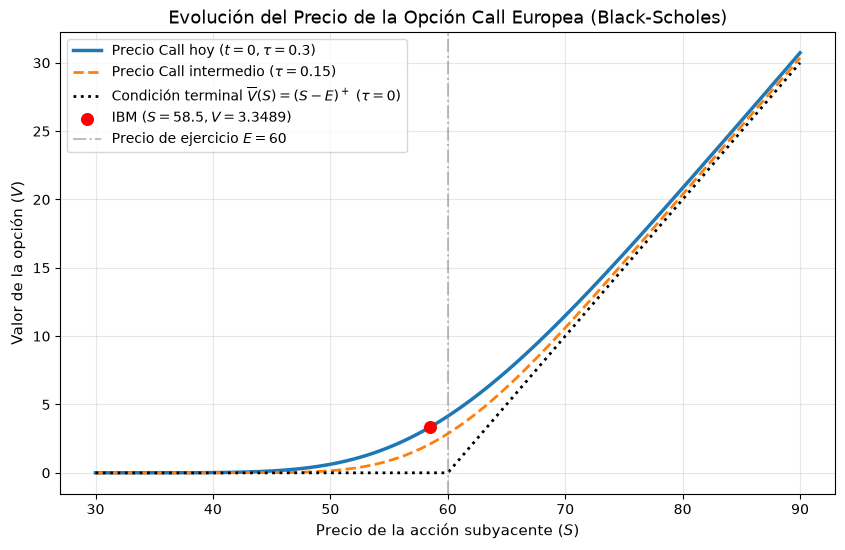

In [28]:
import numpy as np
import matplotlib.pyplot as plt

param_fijos = {E: 60.0, sigma: 0.29, r: 0.04, q: 0.0}
V_expr_num = V_bs_clasica.subs(param_fijos)

# Agregamos 'scipy' para vectorizar correctamente la función erf()
f_call = sp.lambdify((S, tau), V_expr_num, ['numpy', 'scipy'])

S_vals = np.linspace(30, 90, 300)

call_t0 = f_call(S_vals, 0.3)
call_mitad = f_call(S_vals, 0.15)
payoff_T = np.maximum(S_vals - 60.0, 0)

S_ibm = 58.5
V_ibm = float(f_call(S_ibm, 0.3))

plt.figure(figsize=(10, 6))
plt.plot(S_vals, call_t0, label=r'Precio Call hoy ($t=0, \tau=0.3$)', color='#1f77b4', lw=2.5)
plt.plot(S_vals, call_mitad, label=r'Precio Call intermedio ($\tau=0.15$)', color='#ff7f0e', linestyle='--', lw=2)
plt.plot(S_vals, payoff_T, label=r'Condición terminal $\overline{V}(S) = (S - E)^+$ ($\tau=0$)', color='black', linestyle=':', lw=2)

plt.scatter([S_ibm], [V_ibm], color='red', zorder=5, s=70, label=f'IBM ($S={S_ibm}, V={V_ibm:.4f}$)')
plt.axvline(60.0, color='gray', linestyle='-.', alpha=0.5, label='Precio de ejercicio $E = 60$')

plt.title('Evolución del Precio de la Opción Call Europea (Black-Scholes)', fontsize=13)
plt.xlabel('Precio de la acción subyacente ($S$)', fontsize=11)
plt.ylabel('Valor de la opción ($V$)', fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

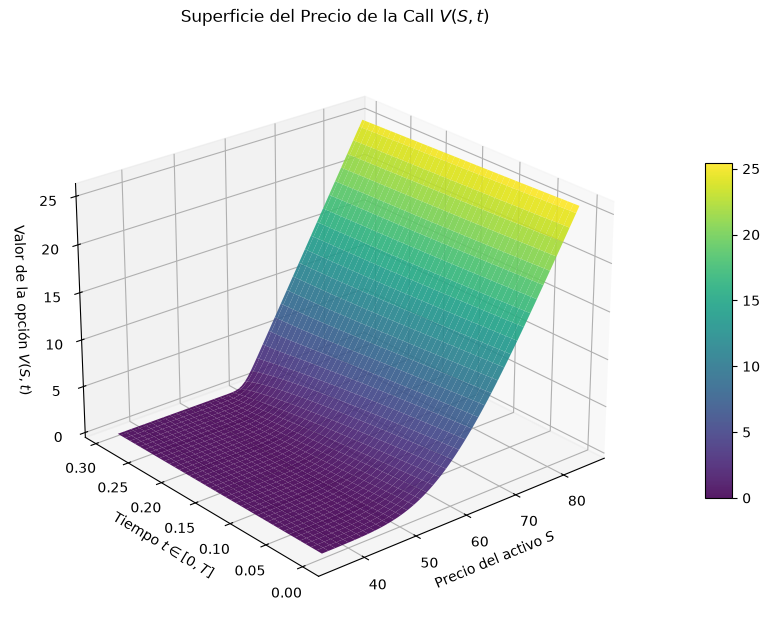

In [29]:
from mpl_toolkits.mplot3d import Axes3D

alpha_num = float(sol_constantes[alpha].subs(param_fijos))
beta_num = float(sol_constantes[beta].subs(param_fijos))

u_expr = sp.exp(alpha_num * x + beta_num * tau) * V_expr_num.subs(S, sp.exp(x))

# Aquí también pasamos ['numpy', 'scipy']
f_calor = sp.lambdify((x, tau), u_expr, ['numpy', 'scipy'])

x_vals = np.linspace(np.log(35), np.log(85), 80)
tau_vals = np.linspace(0.005, 0.3, 80)
X_mesh, TAU_mesh = np.meshgrid(x_vals, tau_vals)
U_mesh = f_calor(X_mesh, TAU_mesh)

S_mesh_vals = np.linspace(35, 85, 80)
t_vals = np.linspace(0, 0.295, 80)
S_mesh, T_mesh = np.meshgrid(S_mesh_vals, t_vals)
V_mesh = f_call(S_mesh, 0.3 - T_mesh)

fig = plt.figure(figsize=(16, 7))

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(S_mesh, T_mesh, V_mesh, cmap='viridis', edgecolor='none', alpha=0.9)
ax2.set_title(r'Superficie del Precio de la Call $V(S, t)$', fontsize=12, pad=12)
ax2.set_xlabel(r'Precio del activo $S$')
ax2.set_ylabel(r'Tiempo $t \in [0, T]$')
ax2.set_zlabel(r'Valor de la opción $V(S, t)$')
ax2.view_init(elev=25, azim=-130)
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=12, pad=0.1)

plt.tight_layout()
plt.show()